# Artificial Intelligence in Health Care - Exercise 1
## Readmission Risk from Structured Clinical Data

Mitglieder: Elbischger Selina, Krauss Marco
Jahrgang: EHT25

Das Ziel dieser Übung ist es das Wiederaufnahmerisiko anhand des Diabetes-Datensatzes zu untersuchen und eine logistische Regression mit einem neuronalen Netz zu vergleichen. Für die Berechechnung des Wiederaufnahemrisikos werden alle bis zu Entlassung verfügbaren Patientendaten miteinbezogen.

### 1 Problem Formulation [1.5P]  

1. **Die klinische Fragestellung:** 
Lässt sich anhand der bis zur Entlassung verfügbaren klinischen Daten vorhersagen, ob ein Patient innerhalb von 30 Tagen erneut stationär aufgenommen wird?


2. **Zielvariable:** Die Zielvariable ist eine erneute stationäre Aufnahme innerhalb von 30 Tagen nach der Entlassung. Die ursprüngliche Variable 'readmitted' besitzt die Ausprägungen <30, >30 und NO. Wir kodieren <30 als 1 und fassen >30 sowie NO zur Klasse 0 zusammen`. Da der Fokus auf frühen Wiederaufnahmen liegt macht diese Binarisierung am meisten Sinn, da Fälle ohne einer oder mit einer späten Wiederaufnahmen für unserenm Fall nicht passen.

3. **Untersuchte Population:** Zur Ermittlung der ein- bzw ausgeschlossenen Fälle wurde die Entlassungsart (discharge_disposition_id) herangezogen. Die zugehörigen Kategorien und ihre Beschreibungen sind in IDS_mapping.csv dokumentiert. Folgende Aufenthalte wurden ausgeschlossen:

    * Personen die verstorben sind (discharge_disposition_id = 11, 19, 20, 21): Eine Wiederaufnahme ist nicht möglich.  
    * Personen die keinen eindeutig abgeschlossenen Aufenthalt haben (discharge_disposition_id = 9, 12): Es ist nicht klar ob eine Entlassung stattgefunden hat. Damit fehlt ein klarer Ausgangspunkt für die Betrachtung einer Wiederaufnahme innerhalb von 30 Tagen.
    *  Personen die in ein Hospiz oder ähnliches entlassen wurden (discharge_disposition_id = 13, 14): einerseits ist die Wahrscheinlichkeit ist höher dass diese Personen zeitnahe versterben andererseits bekommen diese eine intensivere Betreuung.
    * Personen deren Enlassungsart unklar oder nicht dokumentiert ist (discharge_disposition_id = 18, 25, 26): Bei diesen Aufenthalten lässt sich nicht zuverlässig beurteilen, ob die festgelegten Einschlusskriterien erfüllt sind.

4. Zielgruppe (Anwender) sowie eine konkrete Entscheidung, die mithilfe der Vorhersage unterstützt werden soll.    
**Anwender:** Pflegepersonen im Entlassungsmanagement  
**Unterstützte Entscheidung:** Ist für einen Patienten eine intensivere Nachbetreuung notwendig?  
**Begründung:** Das entwickelte Modell soll Pflegepersonen im Rahmen des Entlassungsmanagements unterstützen, Patient:innen mit einem erhöhten Risiko für eine Wiederaufnahme innerhalb von 30 Tagen zu identifizieren. Auf dieser Grundlage können sie bereits vor der Entlassung prüfen, ob zusätzliche Maßnahmen sinnvoll sind, beispielsweise frühere oder häufigere Nachkontrolltermine. Die Vorhersage dient dabei als Ergänzung zur pflegerischen und ärztlichen Einschätzung.

### 2 Data Exploration [2.5P]
Zunächst verschaffen wir uns einen Überblick über die vorhandenen Daten. Dazu untersuchen wir die Datenstruktur, insbesondere die Anzahl der Krankenhausaufenthalte und Spalten sowie die Datentypen der Merkmale. Anschließend betrachten wir die Verteilungen numerischer und kategorialer Merkmale und prüfen auffällige Werte sowie mögliche Ausreißer. Abschließend bestimmen wir die absoluten und relativen Häufigkeiten der Wiederaufnahmekategorien (<30, >30, NO) sowie der daraus abgeleiteten binären Zielvariable.

#### 2a Struktur, Verteilung und Klassenverteilung

In [ ]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
os.environ["KERAS_BACKEND"] = "torch"

import warnings
import torch
import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
print("keras", keras.__version__, "| backend", keras.backend.backend())

In [ ]:
# Datenstruktur untersuchen
# Datensatz importieren
diabetes_orig = pd.read_csv("diabetic_data.csv", na_values=["?"]) # ? bedeutet fehlende Werte

# Größe des Datensatzes
print(f"Der Datensatz hat {diabetes_orig.shape[0]} Zeilen und {diabetes_orig.shape[1]} Spalten.")        #101766 Einträge und 50 Spalten

# erste Zeile anzeigen  |  Identifizieren der nummerischen und kategorischen Variablen und der Outcome-Variable
display(diabetes_orig.head())

# diabetes.info()  #zeigt Spaltennamen, Datentypen und die Anzahl nicht fehlender Einträge
diabetes_orig.isna().sum()   #Überblick über fehlende werte

**Datenstruktur:** Der Datensatz hat 101766 Einträge und 50 Spalten. Jeder Eintrag entspricht einem stationären Krankenhausaufenthalt. Ein Patient kann aufgrund mehrerer Aufenthalte mehrfach im Datensatz vorkommen.  
Anhand der Datensatzbeschreibung (https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008) wurden die Variablen als nummerische oder kategorisch eingeordnet:  
**kategorisch:** race, gender, age, weight, admission_type_id, discharge_disposition_id, admission_source_id, payer_code, medical_specialty, diag_1, diag_2, diag_3, change, diabetesMed, metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone  
**nummerisch:** time_in_hospital, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, number_diagnoses

In [ ]:
#Datensatz bereinigen (Ausschlusskriterien)
ausschluss_id = [    # alle ids der Ausschlusskriterien sammeln
    11, 19, 20, 21,  # Verstorben
    9, 12,           # Kein eindeutig abgeschlossener Aufenthalt
    13, 14,          # Hospiz
    18, 25, 26       # Entlassungsart unklar
]

#in den finalen Datensatz nur jene Einträge aufnehmen die nicht in den Ausschlusskriterien vorkommen und die discharge_disposition_id nicht leer ist
diabetes = diabetes_orig.loc[
    ~diabetes_orig["discharge_disposition_id"].isin(ausschluss_id) # ~ -> Negation, d.h. alle Einträge mit diesen IDs werden ausgeschlossen
    & diabetes_orig["discharge_disposition_id"].notna()         
]

#Kontrolle der Klassenverteilung der Outcomevariable
display(diabetes["readmitted"].value_counts())  #normalize=True -> relative Häufigkeiten anzeigen

#Anzahl der Einträge vor und nach der Bereinigung
print("Aufenthalte vorher:", len(diabetes_orig))
print("Aufenthalte danach:", len(diabetes))
print("Ausgeschlossen:", len(diabetes_orig) - len(diabetes))

#Datensatz in nummerische und kategrosiche Variablen einordnen
numeric_var = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

#kategorisch sind nur jene variablen die im diabtes Datensatz sind und nicht in den nummerischen vorkommen oder eines dieser Variablen sind [...]
categoric_var = [
    column for column in diabetes_orig.columns           
    if column not in numeric_var
    + ["encounter_id", "patient_nbr", "readmitted"]     #readmitted ist OUtcome Variable
]

#Verteilung der nummerischen und kategrosichen Variablen
display(diabetes_orig[numeric_var].describe())

#Verteilung der nummerischen AVriablen als Boxplot darstellen
diabetes_orig[numeric_var].plot(
    kind="box",
    subplots=True,
    layout=(2, 4),
    figsize=(16, 8),
    sharey=False
)

display(diabetes_orig[categoric_var].astype("category").describe())

**Interpretation der Verteilung:**  
Die Verteilungen der numerischen Variablen wurden anhand von Boxplots untersucht. Dabei zeigen mehrere Merkmale potenzielle Ausreißer. Insbesondere bei number_outpatient und num_medications fallen hohe Werte auf.
Laut Datensatzbeschreibung erfasst number_outpatient die Anzahl ambulanter Besuche im gesamten Jahr vor dem jeweiligen Krankenhausaufenthalt. Hohe Werte können daher beispielsweise bei Patienten mit regelmäßigem Behandlungsbedarf grundsätzlich plausibel sein. num_medications beschreibt die Anzahl unterschiedlicher generischer Medikamentenbezeichnungen, die während des gesamten Aufenthalts verabreicht wurden. Die Variable gibt somit weder die Anzahl einzelner Tabletten noch die Anzahl gleichzeitig eingenommener Medikamente an. 
Die auffälligen Werte werden zunächst beibehalten, da ihre Höhe allein keinen Datenfehler belegt und sie als plusibel eingestuft werden. Ihre tatsächliche Richtigkeit lässt sich anhand der verfügbaren Angaben jedoch nicht abschließend bestätigen.
Bei den kategorialen Merkmalen ist die Altersgruppe 70–80 Jahre am häufigsten vertreten. Die Medikamentenvariablen examide und citoglipton enthalten im untersuchten Datensatz ausschließlich die Kategorie „No“ und liefern somit keine Information zur Unterscheidung der Aufenthalte.


In [ ]:

#Outcomevariable in binäre Variable mappen
target_var = diabetes["readmitted"].map({"NO": 0, 
                                         ">30": 0, 
                                         "<30": 1}) 
#target_var hinzufügen
diabetes["readmitted"] = target_var

#Variable change in binäre Variable mappen
diabetes["change"] = diabetes["change"].map({"Ch": 1, "No": 0})
#Variable diabetesMed in binäre Variable mappen
diabetes["diabetesMed"] = diabetes["diabetesMed"].map({"Yes": 1, "No": 0})

#drop examide und citoglipton da diese Variablen nur No beinhelten
diabetes = diabetes.drop(columns=["examide", "citoglipton"])


#Ausgabe der Klassenverteilung in einem DataFrame
class_distr = pd.DataFrame({"Anzahl": target_var.value_counts(),
                            "Anteil (%)": target_var.value_counts(normalize=True) * 100})

display(class_distr.round(2))  #Ausgabe und auf 2 Nachkommastellen runden

Nach Anwendung der Ausschlusskriterien verbleiben 94.639 von ursprünglich 101.766 Aufenthalten. Davon weisen 10.752 Aufenthalte (11,36 %) eine frühe Wiederaufnahme (<30 Tagen) auf. Die übrigen 83.887 Aufenthalte (88,64 %) gehören zur negativen Klasse (>30 Tage oder keine Wiederaufnahme). Es besteht somit ein deutliches Klassenungleichgewicht. Für den späteren Modellvergleich reicht die Accuracy allein daher nicht aus: Ein Modell, das ausschließlich die negative Klasse vorhersagt, würde bereits eine Accuracy von 88,64 % erreichen, ohne eine einzige frühe Wiederaufnahme zu erkennen. Deshalb werden zusätzlich die AUROC, die Sensitivität – der Anteil tatsächlich früher Wiederaufnahmen, die korrekt erkannt werden – sowie die Konfusionsmatrix betrachtet.

#### 2b Aufenthalte vs Patienten
Da wie bereits zuvor erwähnt ein Patient öfters im Datensatz vorkommen kann aufgrund von mehreren Aufenthalten wird im nächsten Schritt die Anzahl der Krankenhausaufenthlte die zum selben Pateinten gehören ermittelt.

In [ ]:
#Anzahl der Aufenthalte pro Patient
display(diabetes.groupby("patient_nbr").size().reset_index(name="Anzahl Aufenthalte")) #.sort_values(by="Anzahl Aufenthalte", ascending=False)   .discribe()

print("Anzahl Aufenthalte:", len(diabetes))
print("Anzahl der Patienten:", diabetes["patient_nbr"].nunique())

#wie viele Patienten jeweils wie viele Aufenthalte haben:
display(diabetes.groupby("patient_nbr").size().value_counts())

Da einzelne Patienten mehrere Krankenhausaufenthalte aufweisen, erfolgt die Aufteilung in Trainings-, Validierungs- und Testdaten gruppiert nach der patient_nbr, sodass alle Aufenthalte eines Patienten ausschließlich einem Teilset zugeordnet werden. Ohne patientenweise Aufteilung könnten Aufenthalte derselben Person in mehreren Teilsets vorkommen, wodurch die Vorhersage aufgrund wiederkehrender ähnlicher Merkmale positiver ausfallen könnte.

#### 2c Missing Values
Im nächsten Schritt wird auf die fehlenden Werte im Datensatz rücksicht genommen. Hierbei werden vor allem die drei Variablen weight, medical_specialty und payer_code beobachtet. Diese werden jeweils in einer Tabelle mit der Anzahl der fehldenden Werte und dem Prozentuellen anteil ausgegeben. Ebenso werden überlegungen angestellt warum es zu fehlenden Werten in diesen Bereichen kommen konnte

In [ ]:
#Anzahl und prozentuellen anteil missingValues der Spalte weight, medical_specialty, payer_code ausgeben
missing_values = pd.DataFrame({"Anzahl missing Values": diabetes[["weight", "medical_specialty", "payer_code", "max_glu_serum", "A1Cresult"]].isna().sum()})
missing_values["Prozentueller Anteil"] = (missing_values["Anzahl missing Values"] / len(diabetes) * 100).round(2)
display(missing_values)


Betrachtet man den prozentuellen Anteil der missing Values kommen wir auf folgende Schlussfolgerungen:  
Bei **weight** fehlen im ursprünglichen Datensatz knapp 97 % der Gewichte. Laut der Informationen aus dem Paper mussten Krankenhäuser das Gewicht vor der HITECH-Gesetzgebung 2009 nicht verpflichtend in strukturierter Form erfassen. Wir entschieden uns gleich wie die Autoren die Variable aufgrund ihrer geringen Anzahl an vorhanden Gewichten zu entfernen. Eine Imputation würde nahezu die gesamte Spalte betreffen und überwiegend auf Annahmen beruhen.  

Die Variable **medical_specialty** beschreibt laut Datensatzbeschreibung die Fachrichtung des aufnehmenden Arztes. Die Fachrichtung kann Hinweise auf die Station des Patienten und den Versorgungskontet geben und wird daher nicht verworfen. Eine Entfernung der gesamten Spalte würde vorhandene Informationen verwerfen; ein Ausschluss aller betroffenen Aufenthalte würde die verfügbare Datenmenge auf knapp 50% reduzieren. Daher wird eine zusätzliche Kategorie IS_MISSING eingeführt, um fehlende Angaben explizit abzubilden und gleichzeitig alle Aufenthalte zu erhalten.   

Im Gegensatz zu meiner Gruppenkollegin schließe ich den **payer_code** aus, für mich gibt es aufgrund von 40% fehlenden Versicherungsträger keinen sinnvollen Zusammenhang.

Die soeben erwähnten Anpassungen werden im folgenden umgesetzt:

In [ ]:
#drop Colum weight
diabetes = diabetes.drop(columns=["weight"])

#drop Colum payer_code
diabetes = diabetes.drop(columns=["payer_code"])

#Tabelle diabetes anzeigen
display(diabetes)

#fehlende Fachrichtung "IS_MISSING" eintragen
diabetes["medical_specialty"] = diabetes["medical_specialty"].fillna("IS_MISSING")


#### 2d Zielpopulation ermitteln
Der 4. Punkt der 2. Aufgabe wurde bereits umgesetzt indem die Entlassungsarten mithilfe des IDS_mapping.csv analysiert wurden. Insgesamt wurden hier 7127 Aufenthalte entfernt; die untersuchte Population umfasst damit 94.639 Aufenthalte. Eine genauere Erläuterung diesbezüglich ist in Aufgabe 1 'Problem Formulation' nachzulesen.

#### 2e ICD-9 Code Gruppierung
Die ICD-9-Codes weisen eine hohe Anzahl unterschiedlicher Kategorien auf. Deshalb werden sie anhand eines einheitlichen, klinisch begründeten Schemas zu übergeordneten Diagnosegruppen zusammengefasst. Dies reduziert die Anzahl seltener Kategorien und ermöglicht eine übersichtlichere Verarbeitung der Diagnoseinformationen.

In [ ]:
#Häufigkeit von diagnoses in den Spalten diag_1, diag_2, diag_3
diagnoses = pd.concat([diabetes["diag_1"]])
display(diagnoses.value_counts().head(20))  #die 20 häufigsten hauptdiagnosen
diagnoses = pd.concat([diabetes["diag_2"]])
display(diagnoses.value_counts().head(20))  #die 20 häufigsten Nebendiagnosen
diagnoses = pd.concat([diabetes["diag_3"]])
display(diagnoses.value_counts().head(20))  #die 20 häufigsten weiteren hauptdiagnosen


diagnoses_cols = ["diag_1", "diag_2", "diag_3"]

display(pd.DataFrame({
    "Unterschiedliche ICD-9-Codes": diabetes[diagnoses_cols].nunique(),
    "Fehlende Codes": diabetes[diagnoses_cols].isna().sum()
}))

Im ersten Schritt wurde ein Überblick über die Diagnosedaten erstellt. Dazu wurden für jede der drei Diagnosespalten die 20 häufigsten Codes sowie die Anzahl unterschiedlicher und fehlender Diagnosecodes ermittelt.
Aufgrund der hohen Anzahl unterschiedlicher Codes wurde ein bereits vorhandenes Gruppierungsschma gewählt. Als Grundlage dient die Einteilung aus Table 2 der Originalpublikation. Die Autoren fassen dort die Hauptdiagnosen zu übergeordneten Krankheitsgruppen zusammen. Diagnosegruppen, die jeweils weniger als 3,5 % der untersuchten Aufenthalte ausmachen, werden unter „Sonstiges“ zusammengefasst.

Für die Zuteilung der ICD-9-Codes wird eine Funktion definiert und auf allen drei Spalten angewendet.

In [ ]:
#Funktion zur Kategorisierung der Diagnosen
def get_diag_group(diag_code):
    #überprüfen ob code leer ist
    if pd.isna(diag_code):
        return "Fehlender Code"

    #wenn nciht dann code als string und leerzeichen entfernen (und in Großbuchstaben umwandeln) für Einheitliche abfragen
    diag_code = str(diag_code).strip().upper()

    #Codes mit E und V der Gruppe Sonstiges zuteilen
    if diag_code.startswith("V") or diag_code.startswith("E"):
        return "Sonstige"

    #Hauptcode bestimmen (nur 250 statt 250.13) -> ist selbe Kategorie
    try :
        icd9_code = int(diag_code.split(".")[0])  #nur der Hauptcode (vor dem Punkt)
    except ValueError:
        return "Fehlerhafter Code"

    #Zuteilung zu Gruppe abhängig vom "Hauptcode"
    if 390 <= icd9_code <= 459 or icd9_code == 785:
        return "Kreislauferkrankungen"
    elif 460 <= icd9_code <= 519 or icd9_code == 786:
        return "Atmungserkrankungen"
    elif 520 <= icd9_code <= 579 or icd9_code == 787:
        return "Verdauungserkrankungen"
    elif icd9_code ==250:
        return "Diabetes"
    elif 800 <= icd9_code <= 999:
        return "Verletzungen"
    elif 710 <= icd9_code <= 739:
        return "Muskuloskeletterkrankungen"
    elif 580 <= icd9_code <= 629 or icd9_code == 788:
        return "Genitourinäre Erkrankungen"
    elif 140 <= icd9_code <= 239:
        return "Neoplasmen" 
    else:
        return "Sonstige"


#Ergebnis in neuen Spalten speichern
for col in diagnoses_cols:
    diabetes[f"{col}_group"] = diabetes[col].apply(get_diag_group)      #diag_code ist Inhalt der aktuellen Zeile von col #.apply übergibt jeden Wert dieser Spalte einzeln an die Funktion.


#Kontrolle der Kategorisierung der Diagnosen anzeigen (Anzeigen der beiden zusammengehörigen relevanten Spalten mit ersten 10 Datensätzen)
display(diabetes[
    ["diag_1", "diag_1_group",
     "diag_2", "diag_2_group",
     "diag_3", "diag_3_group"]
].head(10))

#Anzahl der jeweiligen Diagnosen in der jeweiligen Gruppe (auswahl der Spalte)
for col in ["diag_1_group", "diag_2_group", "diag_3_group"]:
    display(diabetes[col].value_counts())

Durch die Gruppierung der einzelnen ICD-9-Codes konnte die Anzahl der unterschiedlichen Diagnosen, die je nach Diagnosefeld zwischen 712 und 782 lag, auf neun übergeordnete Krankheitsgruppen reduziert werden. Dabei wurden Hauptdiagnosen, Nebendiagnosen und weitere Nebendiagnosen jeweils separat gruppiert und in neuen Spalten gespeichert.

Der Vergleich der drei resultierenden Diagnosegruppen zeigt, dass Herzerkrankungen sowohl bei den Hauptdiagnosen als auch bei den Nebendiagnosen am häufigsten vorkommen, gefolgt von der Gruppe „Sonstige Diagnosen“. Bei den Nebendiagnosen und den weiteren Nebendiagnosen steht Diabetes jeweils an dritter Stelle.

Auffällig ist außerdem, dass lediglich 18 Fälle keine dokumentierte Hauptdiagnose aufweisen. Die Anzahl der fehlenden Diagnosecodes nimmt hingegen von den Hauptdiagnosen über die Nebendiagnosen bis zu den weiteren Nebendiagnosen zu. Dies könnte darauf hindeuten, dass insbesondere zusätzliche Diagnosen nicht immer vollständig dokumentiert wurden, beispielsweise aufgrund von Unterschieden in der Dokumentationspraxis oder im klinischen Alltag. Die tatsächlichen Ursachen für die fehlenden Angaben lassen sich aus den vorliegenden Daten jedoch nicht eindeutig ableiten.

### Preprocessing 
Bevor die logistische Regression und das neuronale Netz trainiert werden, erfolgt die Vorverarbeitung der Daten. Dabei orientieren wir uns an den Schritten des bereitgestellten Notebooks NB2.  
Der Datensatz wird patientenweise in 60 % Trainingsdaten, 25 % Testdaten und 15 % Validierungsdaten aufgeteilt.
Die beiden Variablen examide und citoglipton werden nicht in die Features aufgenommen, da sie nur die Antwort No enthalten und somit keine zusätzliche Information liefern.

In [ ]:
#Features definieren (alle Spalten außer Outcomevariable und IDs und den ursprünglichen Diagnosenspalten) sortiert nach der Patient_id
X_df = diabetes.drop(columns=[
    "readmitted",   # Zielvariable
    "encounter_id", # Aufenthalts-ID
    "patient_nbr",  # Patienten-ID
    "diag_1",       # ursprünglichen Diagnosecodes irrelevant, da wir die Gruppierung verwenden
    "diag_2",
    "diag_3"
]).copy()

# Zielvariable definieren (1 = <30 Tage, 0 = >30 Tage oder keine Wiederaufnahme) sortiert nach der Patient_id
y = (diabetes["readmitted"] == 1).astype(int).values

#Einteilung der Patiente in Gruppen, damit die Aufteilung in Trainings-, Validierungs- und Testset patientenbasiert erfolgt (d.h. alle Aufenthalte eines Patienten sind in einem Set)
groups = diabetes["patient_nbr"]

from sklearn.model_selection import GroupShuffleSplit
SEED = 42  # Zufallszahl für Reproduzierbarkeit

#zufällige Aufteilung der Patienten in Trainings-, Validierungs- und Testset (60% / 25% / 15%)
split = GroupShuffleSplit(n_splits=1, train_size=0.6, random_state=SEED)
train_idx, tmp_idx = next(split.split(X_df, y, groups=groups))      #groups sorgt dafür, dass alle Aufenthalte eines Patienten in einem Set sind
                                                                    #Ausgabe = ZEILENPOSITIONEN, keine Patienten-IDs

#Trainigsdatensatz in X_train und y_train aufteilen -> ilco wählt Zeilenpositionen aus
#gleiche Position für x und y
X_train_df = X_df.iloc[train_idx]
Y_train = y[train_idx]


#temporärer Datensatz für Validierung und Testset speichern
X_tmp = X_df.iloc[tmp_idx]
Y_tmp = y[tmp_idx]
#Gruppen für temporären Datensatz speichern
groups_tmp = groups.iloc[tmp_idx]  

# train_size=0,653 --> immer der erste zurückgegebene Indexsatz --> Herleitung => 40 Aufteilen auf 25 und 15 -> 25/40 = 0,625
#2.Test und Validierungsdatensatz aufteilen (25% / 15%)
split = GroupShuffleSplit(n_splits=1, train_size=0.375, random_state=SEED)  #0.375 * 0.4 = 0.15
val_idx, test_idx = next(split.split(X_tmp, Y_tmp, groups=groups_tmp))     #neue Positionen für Validierungs- und Testset
#Wir verwenden 25 % der Daten als Testset, weil ein größeres Testset eine stabilere und verlässlichere Schätzung der finalen Modellleistung ermöglicht. 
#Dadurch erhoffen wir uns, Unterschiede zwischen logistischer Regression und neuronalem Netz besser beurteilen zu können.

#Validierungsset in X_val und y_val aufteilen
X_val_df = X_tmp.iloc[val_idx]
Y_val = Y_tmp[val_idx]

#test set in X_test und y_test aufteilen
X_test_df = X_tmp.iloc[test_idx]
Y_test = Y_tmp[test_idx]


#Korrekte Aufteilung der Datensätze überprüfen -> Sets mit den jeweiligen Patienten-IDs erstellen
train_patients = set(groups.iloc[train_idx])        #set() -> Menge mit eindeutigen Werten
val_patients = set(groups_tmp.iloc[val_idx])
test_patients = set(groups_tmp.iloc[test_idx])

#Überprüfen, ob es Überschneidungen zwischen den Sets gibt
display({train_patients.isdisjoint(val_patients)})      #isdisjoint() = true wenn keine Überschneidung
display({train_patients.isdisjoint(test_patients)})
display({val_patients.isdisjoint(test_patients)})
        

#Ausgabe
print(f"train {len(Y_train):>4}  ({100*Y_train.mean():.1f}% positive)")
print(f"val   {len(Y_val):>4}  ({100*Y_val.mean():.1f}% positive)")
print(f"test  {len(Y_test):>4}  ({100*Y_test.mean():.1f}% positive)")



Nachdem der Datensatz in 3 Splits aufgeteilt wurde werden im nächsten Schritt die Variablen in nummerische und ktegorische und binäre features gegliedert udn für diese jeweils die Missing values imputiert, sie standartisiert und die preprosessing pipeline aufgebaut.

In [ ]:

NUMERIC = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]
CATEGORICAL = [
    "gender",
    "age",
    "race",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "medical_specialty",
    "diag_1_group",
    "diag_2_group",
    "diag_3_group",
    "max_glu_serum",
    "A1Cresult",
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "acetohexamide",
    "glipizide",
    "glyburide",
    "tolbutamide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "insulin",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone",
    "change", 
    "diabetesMed"
]

#Preprocessing pipeline für alle drei Featuresets erstellen (numerische, kategoriale und binäre Variablen)
prep = ColumnTransformer([
      ("num", Pipeline([("impute", SimpleImputer(strategy="median")),   #numerische Variablen: fehlende Werte mit Median ersetzen und Standardisierung
                        ("scale",  StandardScaler())]), NUMERIC),
      ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),    
                        ("onehot", OneHotEncoder(drop="first",      #Kategorische Variablen: fehlende Werte mit häufigstem Wert ersetzen und One-Hot-Encoding durchführen
                                                 handle_unknown="ignore"))]),   #One-Hot-Encoding = wandelt Kategorien in eigene Spalten um, wobei 1 das Vorliegen einer Kategorie und 0 deren Abwesenheit kennzeichnet.
                                                 CATEGORICAL),
])

 
#Prerocessing auf Trainingsset fitten, Validierungs- und Testset nur anwenden
X_train = prep.fit_transform(X_train_df).astype("float32") 
X_val = prep.transform(X_val_df).astype("float32")
X_test = prep.transform(X_test_df).astype("float32")

n_cat = len(CATEGORICAL) #zählen der variable
#print(n_cat)

y_train_f = Y_train.astype("float32")
y_val_f = Y_val.astype("float32")


print(n_cat, "->", X_train.shape[1], "model inputs")
print("shapes:", X_train.shape, X_val.shape, X_test.shape)

### 3 Baseline logistiusche Regression: 

Nach Abschluss der Datenvorverarbeitung wird eine logistische Regression als Baseline trainiert. Sie dient als Referenz für den späteren Vergleich mit dem neuronalen Netz.

In [ ]:
lr_model = LogisticRegression(max_iter=2000)
lr_model.fit(X_train, Y_train)

# Nur Validierung! Das Testset darf nur einmal verwendet werden zum schluss
p_va_lr = lr_model.predict_proba(X_val)[:, 1]
auc_lr_val = roc_auc_score(Y_val, p_va_lr)

print("logistic regression   Validation-AUROC %.4f" % auc_lr_val)


**Ergebnis der Baseline:** Die logistische Regression erreicht auf dem Validierungsset eine AUROC von 0,65. 
Das Modell unterscheidet frühe Wiederaufnahmen damit besser als der Zufall (AUROC = 0,5), die Trennfähigkeit ist aber nur moderat. 
Das passt zur Literatur: Wiederaufnahme-Vorhersagen aus strukturierten Abrechnungsdaten erreichen typischerweise AUROC-Werte um 0,6–0,7, weil viele Ursachen einer Wiederaufnahme (soziale Situation, Adhärenz, Versorgung nach der Entlassung) gar nicht im Datensatz stehen. 
Dieser Wert ist die Zahl, die das neuronale Netz schlagen muss.

### 4 Neural Network and Regularization

Wir orientieren uns am Aufbau aus NB2 (§6 und §7). Wegen der Datensatzgröße (ca. 57.000 Trainingsaufenthalte statt 181 Patienten in NB2) verwenden wir eine Batchgröße von 256 statt 32. Mit 32 hätte jede Epoche ca. 1.800 Update-Schritte und das Training vieler Konfigurationen wäre auf einem Laptop zu langsam. Wir trainieren maximal 50 Epochen. 
Vorgehen:
- **4a** Kapazität variieren (Anzahl Hidden Layers und Hidden Units), ohne Regularisierung
- **4b** Regularisierung variieren (Early Stopping, Dropout, L2/Weight Decay)
- **4c** Optimierer vergleichen (Adam, SGD mit Momentum, RMSprop)
- **4d** Run-to-run-Variation über mehrere Seeds und finale Modellauswahl am Validierungsset

Jede Konfiguration wird mit `keras.utils.set_random_seed(SEED)` geseedet. Ausgewählt wird nur anhand der Validierungs-AUROC.

#### 4a Hidden Layers herausfinden

In [ ]:
n_features = X_train.shape[1]   # Anzahl der Inputs nach dem Preprocessing
EPOCHS = 50                     # maximale Anzahl Epochen
BATCH  = 256                    # größer als in NB2, weil der Datensatz viel größer ist
results = []                    # hier sammeln wir alle Ergebnisse für eine Übersichtstabelle

# Funktion für die Architektur (wie build_reg in NB2, aber mit variabler Layer-Anzahl)
def build_model(units=(64, 32), p_drop=0.0, l2=0.0, optimizer="adam", n_in=None):
    reg = keras.regularizers.l2(l2) if l2 else None     # L2 nur wenn l2 > 0
    n_in = n_in or n_features

    m = keras.Sequential([layers.Input(shape=(n_in,))])
    for u in units:                                      # pro Eintrag in units ein Hidden Layer
        m.add(layers.Dense(u, activation="relu", kernel_regularizer=reg))
        m.add(layers.Dropout(p_drop))                    # bei p_drop=0 passiert nichts
    m.add(layers.Dense(1))                               # Ausgabeneuron ohne Aktivierung -> Logit

    # Auswahl des Optimierers
    if optimizer == "adam":
        opt = keras.optimizers.Adam(learning_rate=1e-3)
    elif optimizer == "sgd":
        opt = keras.optimizers.SGD(learning_rate=1e-2, momentum=0.9)   # SGD braucht größere Lernrate
    elif optimizer == "rmsprop":
        opt = keras.optimizers.RMSprop(learning_rate=1e-3)
    else:
        raise ValueError("Unbekannter Optimierer: " + optimizer)

    m.compile(optimizer=opt,
              loss=keras.losses.BinaryCrossentropy(from_logits=True),
              metrics=[keras.metrics.AUC(from_logits=True, name="auc")])
    return m

# Logits -> Wahrscheinlichkeiten (wie in NB2)
def probs(model, A):
    return 1 / (1 + np.exp(-model.predict(A, verbose=0).ravel()))

# Training + Auswertung auf dem Validierungsset (wie run_reg in NB2)
# data: optional andere Daten (brauchen wir in Aufgabe 6 für den Random Split)
def run_reg(label, epochs=EPOCHS, early=False, seed=SEED, data=None, **kw):
    if data is None:
        data = (X_train, y_train_f, X_val, y_val_f, Y_val)
    Xtr, ytr, Xva, yva, yva_int = data

    keras.utils.set_random_seed(seed)                    # reproduzierbar
    m = build_model(n_in=Xtr.shape[1], **kw)

    cbs = []
    if early:
        cbs = [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max",
                                             patience=10,                 # 10 Epochen ohne Verbesserung -> Stopp
                                             restore_best_weights=True)]  # beste Gewichte zurückholen

    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=epochs,
              batch_size=BATCH, verbose=0, callbacks=cbs)

    auc = roc_auc_score(yva_int, probs(m, Xva))
    results.append({"Konfiguration": label, "Epochen": len(h.history["loss"]), "val AUROC": round(auc, 4)})
    print(f"{label:<34} epochs run {len(h.history['loss']):>3}   val AUROC {auc:.4f}")
    return label, m, h, auc

# Lernkurven plotten (wie in NB2, aber für beliebig viele Runs, max. 4 pro Zeile)
def plot_runs(runs, title=""):
    n = len(runs)
    ncols = min(4, n)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 2.9 * nrows),
                             sharey=True, squeeze=False)
    axes = axes.ravel()
    for ax, (label, _, h, auc) in zip(axes, runs):
        ax.plot(h.history["loss"], color="0.3", lw=1.4, label="train")
        ax.plot(h.history["val_loss"], color="#b53a36", lw=1.4, label="validation")
        best = int(np.argmax(h.history["val_auc"]))      # Epoche mit bester val AUC
        ax.axvline(best, color="#b53a36", ls=":", lw=1)
        ax.set_title(f"{label}\nval AUROC {auc:.3f}", fontsize=8)
        ax.set_xlabel("epoch")
    for ax in axes[n:]:                                  # leere Subplots ausblenden
        ax.axis("off")
    axes[0].set_ylabel("binary cross-entropy"); axes[0].legend(fontsize=7)
    fig.suptitle(title, fontsize=10)
    plt.tight_layout(); plt.show()

In [ ]:
# 4a: Kapazität variieren, OHNE Regularisierung
runs_cap = [
    run_reg("1 Layer: 32",            units=(32,)),
    run_reg("2 Layer: 32/16",         units=(32, 16)),
    run_reg("2 Layer: 64/32 (Basis)", units=(64, 32)),
    run_reg("2 Layer: 128/64",        units=(128, 64)),
    run_reg("3 Layer: 128/64/32",     units=(128, 64, 32)),
]
plot_runs(runs_cap, "4a: Kapazität (ohne Regularisierung)")

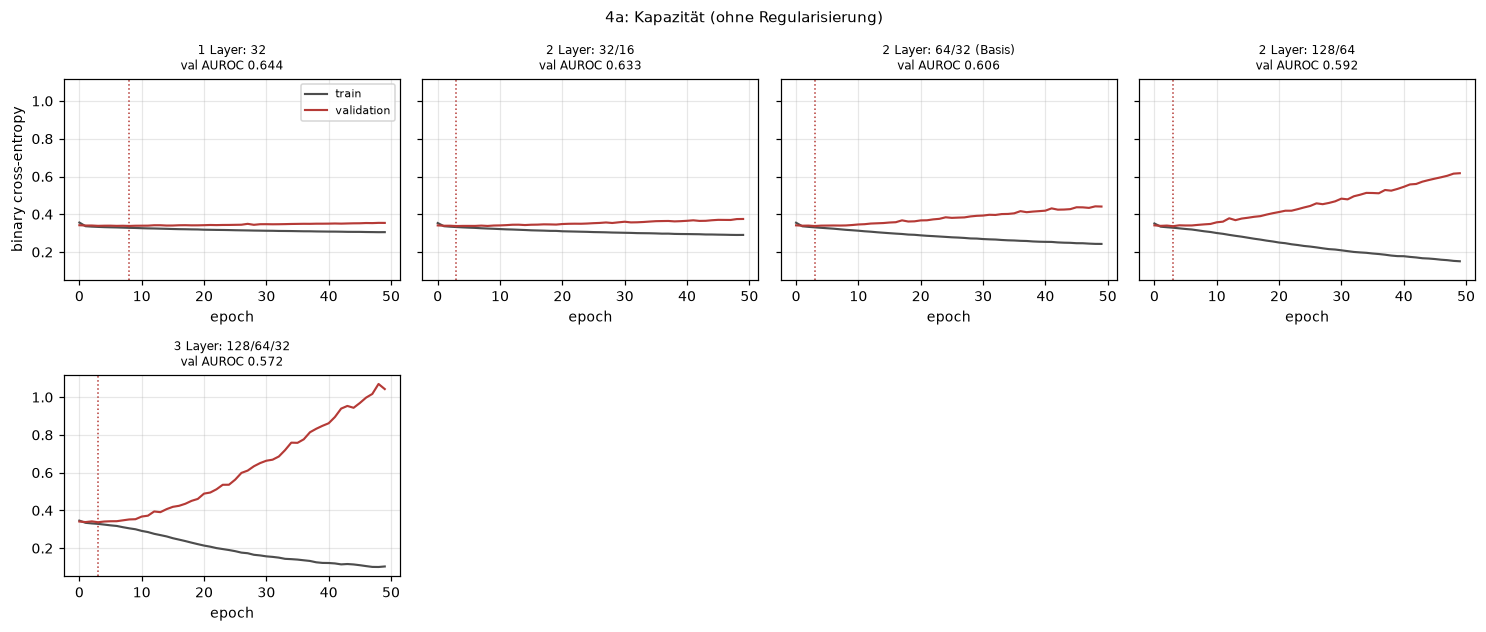

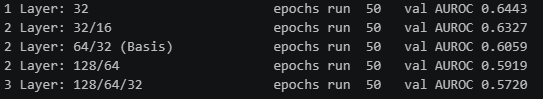

**Interpretation 4a:**
Bei allen Netzen sinkt der Trainingsverlust stetig, der Validierungsverlust steigt aber schon nach wenigen Epochen wieder an (beste Epoche ca. 3, beim 32er-Netz ca. 8). Das Netz overfittet also, wie in NB2. 
Je größer das Netz, desto stärker ist das Overfitting: Beim 1-Layer-Netz mit 32 Neuronen bleiben die Kurven fast parallel (val AUROC 0,644), beim 3-Layer-Netz steigt der Validierungsverlust auf über 1,0 (val AUROC 0,572). Kein Netz ist besser als die logistische Regression (0,652). 
Da die größeren Netze (128/64 und 128/64/32) am stärksten overfitten und am schlechtesten abschneiden, arbeiten wir in 4b mit den drei kleineren Netzen weiter (32, 32/16 und 64/32) und testen, ob Regularisierung das Overfitting verringert.

#### 4b Auf Basis der Kapazität Regularieserer herausfinden

In [ ]:
# 4b: Regularisierer auf den drei kleineren Netzen aus 4a testen
CAPS = {"32": (32,), "32/16": (32, 16), "64/32": (64, 32)}

runs_reg = []
for name, units in CAPS.items():
    runs_reg += [
        run_reg(f"{name} + Early Stopping",     units=units, early=True),
        run_reg(f"{name} + Dropout 0.3",        units=units, p_drop=0.3),
        run_reg(f"{name} + L2 1e-3",            units=units, l2=1e-3),
        run_reg(f"{name} + Dropout 0.3 + ES",   units=units, p_drop=0.3, early=True),
    ]

plot_runs(runs_reg, "4b: Regularisierung")

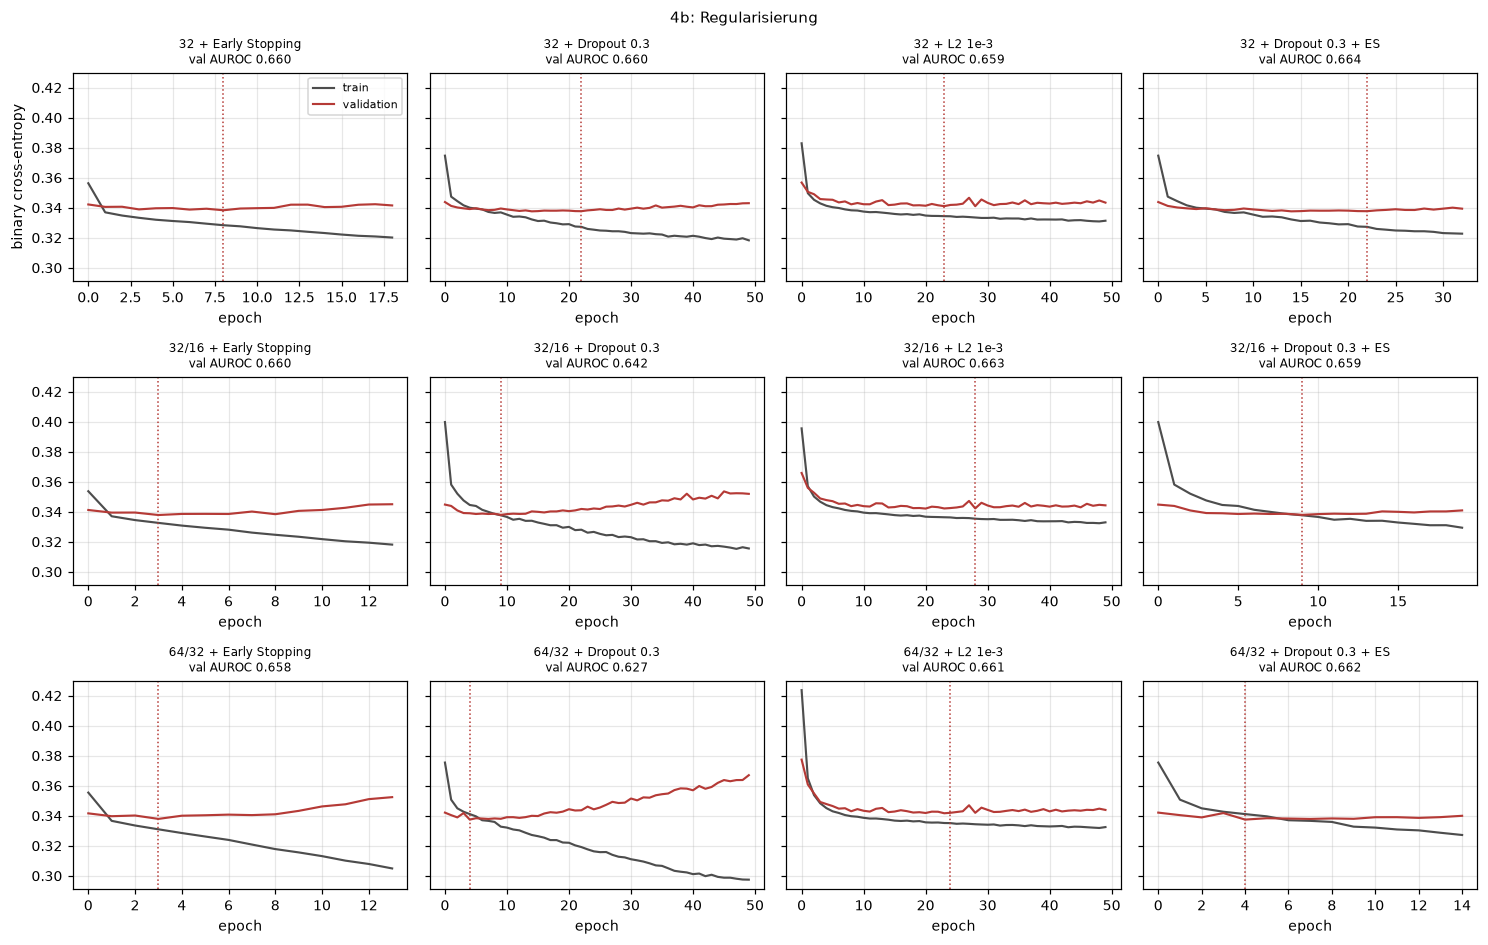

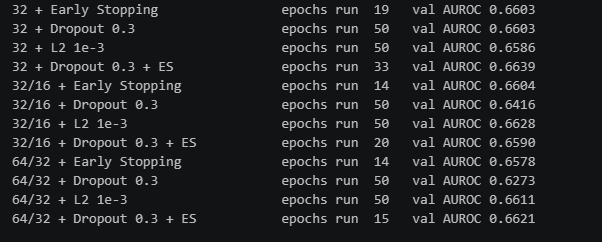

**Interpretation 4b:**
Mit Regularisierung verbessern sich alle drei Netze deutlich gegenüber 4a (z. B. 64/32: von 0,606 auf bis zu 0,662). Fast alle Varianten liegen jetzt bei einer val AUROC von ca. 0,66 und damit knapp über der logistischen Regression (0,652).
- **Early Stopping:** Das Training stoppt nach 14–19 Epochen, bevor das Overfitting beginnt. Funktioniert bei allen Netzen gleich gut (ca. 0,66).
- **Dropout 0.3 (ohne Early Stopping):** Beim 32er-Netz reicht das aus (0,660). Bei 32/16 und 64/32 steigt der Validierungsverlust trotzdem nach ca. 10 Epochen wieder an, die AUROC ist schlechter (0,642 bzw. 0,627). Dropout allein reicht bei den größeren Netzen also nicht.
- **L2 1e-3:** Trainings- und Validierungskurve bleiben über alle 50 Epochen nah beieinander, es tritt praktisch kein Overfitting mehr auf (ca. 0,66).
- **Dropout 0.3 + Early Stopping:** Bestes Ergebnis beim 32er-Netz (0,664).

Die Unterschiede zwischen den regularisierten Varianten sind aber sehr klein (meist unter 0,005). Ob sie echt sind oder nur Zufall, prüfen wir in 4d mit mehreren Seeds. Für 4c verwenden wir die beste Kombination, das einfachste Netz (32) mit Dropout 0.3 und Early Stopping.

#### 4c Auf Basis BEST (Capacity und Regularizes) optimizer festlegen

In [ ]:
# 4c: Optimierer vergleichen, auf Basis der besten Kapazität + Regularisierung aus 4b
CAP = (32,)                               # beste Kapazität aus 4b
BEST_REG = dict(p_drop=0.3, early=True)   # bester Regularisierer aus 4b

runs_opt = [
    run_reg("Adam (lr 1e-3)",           units=CAP, optimizer="adam",    **BEST_REG),
    run_reg("SGD + Momentum (lr 1e-2)", units=CAP, optimizer="sgd",     **BEST_REG),
    run_reg("RMSprop (lr 1e-3)",        units=CAP, optimizer="rmsprop", **BEST_REG),
]
plot_runs(runs_opt, "4c: Optimierer")

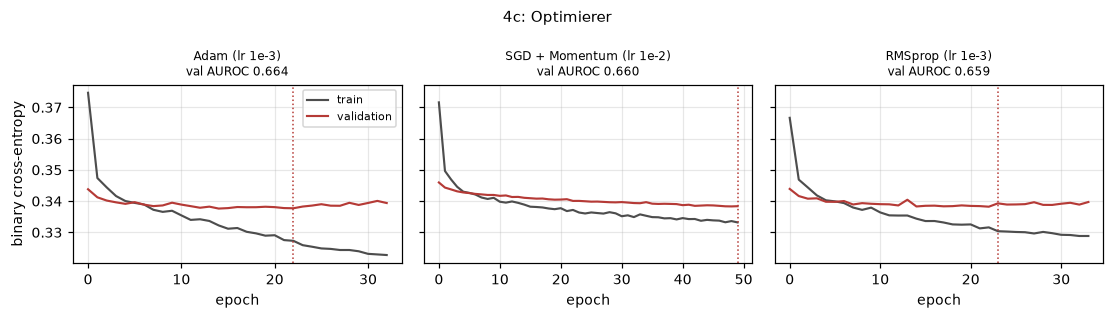

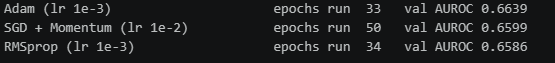

**Interpretation 4c:**
Alle drei Optimierer erreichen ein ähnliches Ergebnis (val AUROC 0,659–0,664). 
- **Adam:** Der Verlust sinkt in den ersten Epochen am schnellsten, die beste Epoche ist ca. 22 (0,664).
- **SGD mit Momentum:** Lernt deutlich langsamer. Die beste Epoche liegt erst bei 49, d. h. das Netz hat sich nach 50 Epochen noch leicht verbessert und Early Stopping hat nicht gegriffen (0,660). Mit mehr Epochen wäre SGD vermutlich ähnlich gut wie Adam.
- **RMSprop:** Verhält sich ähnlich wie Adam, die Validierungskurve schwankt etwas stärker (0,659).

Der Optimierer beeinflusst hier vor allem, wie schnell das Netz lernt, aber kaum das Endergebnis. Wir bleiben bei Adam, da er am schnellsten konvergiert und den besten Wert erreicht.

#### 4d Bestes Modell 

In [ ]:
# 4d: Wie stark schwankt das Ergebnis nur durch den Zufall (Gewichtsinitialisierung, Dropout, Batch-Reihenfolge)?
BEST = dict(units=CAP, optimizer="adam", **BEST_REG)   # finale Konfiguration: 32, Dropout 0.3, ES, Adam

seed_aucs = [run_reg(f"BEST, seed {s}", seed=s, **BEST)[3] for s in [0, 1, 2, 3, 4]]
print(f"\nBEST über 5 Seeds: val AUROC = {np.mean(seed_aucs):.4f} ± {np.std(seed_aucs):.4f}")
print(f"Logistische Regression:        val AUROC = {auc_lr_val:.4f}")

# Übersichtstabelle aller Konfigurationen
display(pd.DataFrame(results).sort_values("val AUROC", ascending=False).reset_index(drop=True))

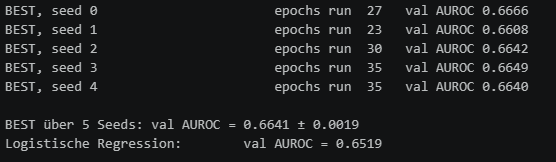

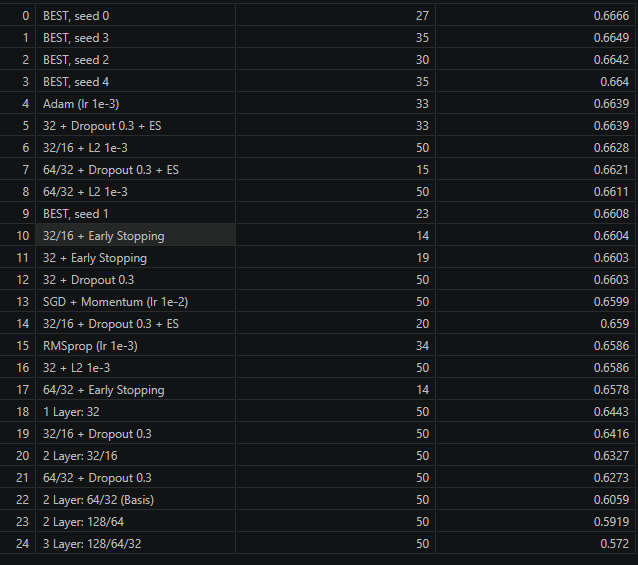

**Interpretation 4d:**
Wir haben das beste Modell (32 Neuronen, Dropout 0.3, Early Stopping, Adam) mit 5 verschiedenen Seeds trainiert. Die val AUROC liegt zwischen 0,661 und 0,667 (Mittelwert 0,664 ± 0,002). Das ist die Schwankung, die nur durch den Zufall entsteht (Startgewichte, Dropout, Reihenfolge der Batches).

Damit können wir unsere bisherigen Ergebnisse einordnen:
- **Echt** ist der Unterschied zwischen den Netzen ohne Regularisierung (4a, 0,57–0,64) und mit Regularisierung (ca. 0,66). Dieser ist viel größer als die Seed-Schwankung.
- **Echt** ist auch, dass das Netz auf dem Validierungsset bei allen Seeds über der logistischen Regression (0,652) liegt. Der Abstand ist mit ca. 0,01 aber klein.
- **Nicht messbar** sind die Unterschiede zwischen den Regularisierern und den Optimierern (4b, 4c). Diese liegen innerhalb der Schwankung, wir können also z. B. nicht sagen, dass Dropout besser als L2 ist.

**Finales Modell:** 1 Hidden Layer mit 32 Neuronen, Dropout 0.3, Early Stopping, Adam. Ob das Netz auch auf dem Testset besser ist, prüfen wir in Aufgabe 5.

### 5 Comparison and Limitations [1P]
Jetzt verwenden wir das Testset genau einmal und werten beide Modelle auf demselben (patientenweise gruppierten) Testset aus.
Für die Konfusionsmatrix brauchen wir eine Schwelle. Da nur ca. 11 % der Aufenthalte positiv sind, würde die Schwelle 0,5 fast niemanden als positiv vorhersagen. Wir verwenden deshalb für beide Modelle den Anteil der Positiven im Trainingsset (ca. 0,11) als Schwelle. Die Schwelle ist nicht optimiert, aber beide Modelle werden gleich behandelt.

In [ ]:
from sklearn.metrics import roc_curve

# finales Netz mit dem Standard-SEED trainieren (reproduzierbar)
_, nn_final, h_final, _ = run_reg("FINAL Netz", **BEST)

# EINMALIGE Auswertung auf dem Testset
p_te_nn = probs(nn_final, X_test)
p_te_lr = lr_model.predict_proba(X_test)[:, 1]

auc_nn_test = roc_auc_score(Y_test, p_te_nn)
auc_lr_test = roc_auc_score(Y_test, p_te_lr)
print(f"Test AUROC  logistische Regression: {auc_lr_test:.4f}")
print(f"Test AUROC  neuronales Netz:        {auc_nn_test:.4f}")
print(f"Differenz (NN - LR):                {auc_nn_test - auc_lr_test:+.4f}")

# Konfusionsmatrix bei gleicher Schwelle für beide Modelle
thr = Y_train.mean()
print(f"\nSchwelle = {thr:.3f}")
for name, p in [("Logistische Regression", p_te_lr), ("Neuronales Netz", p_te_nn)]:
    tn, fp, fn, tp = confusion_matrix(Y_test, (p >= thr).astype(int)).ravel()
    print(f"\n{name}")
    display(pd.DataFrame([[tn, fp], [fn, tp]],
                         index=["echt: keine frühe WA", "echt: frühe WA"],
                         columns=["vorhergesagt: 0", "vorhergesagt: 1"]))
    print(f"Sensitivität {tp/(tp+fn):.3f}   Spezifität {tn/(tn+fp):.3f}   PPV {tp/(tp+fp):.3f}")

# ROC-Kurven beider Modelle
plt.figure(figsize=(4.5, 4.5))
for name, p, auc in [("LR", p_te_lr, auc_lr_test), ("NN", p_te_nn, auc_nn_test)]:
    fpr, tpr, _ = roc_curve(Y_test, p)
    plt.plot(fpr, tpr, lw=1.4, label=f"{name} (AUROC {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("1 - Spezifität"); plt.ylabel("Sensitivität")
plt.title("ROC Testset"); plt.legend()
plt.tight_layout(); plt.show()

# Ist der Unterschied echt? Einfaches Bootstrap auf dem Testset (1000 Ziehungen mit Zurücklegen)
rng = np.random.default_rng(SEED)
n = len(Y_test)
diffs = []
for _ in range(1000):
    idx = rng.integers(0, n, n)
    diffs.append(roc_auc_score(Y_test[idx], p_te_nn[idx]) - roc_auc_score(Y_test[idx], p_te_lr[idx]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"\nDifferenz NN - LR: {auc_nn_test - auc_lr_test:+.4f}   95%-Bootstrap-Intervall [{lo:+.4f}, {hi:+.4f}]")

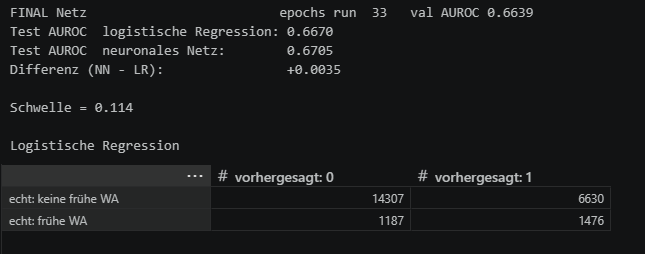

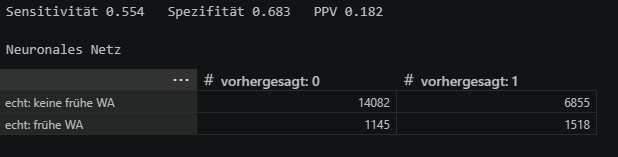

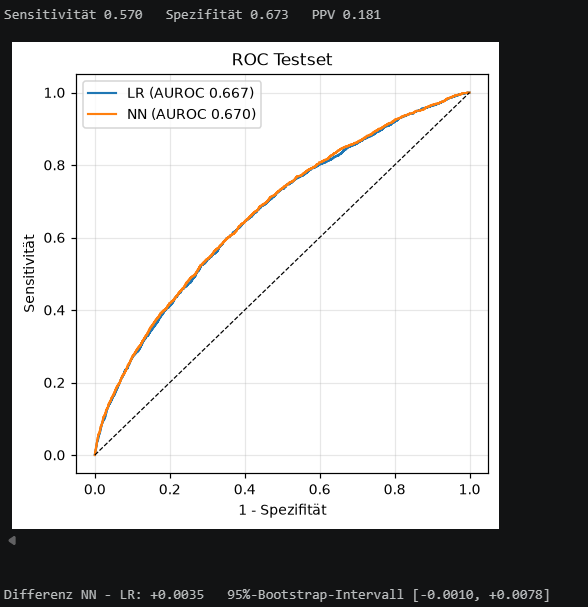

**Ergebnis:** Auf dem Testset erreicht die logistische Regression eine AUROC von 0,667, das neuronale Netz 0,671. Die Differenz beträgt nur 0,0035, das 95%-Bootstrap-Intervall der Differenz reicht von −0,001 bis +0,008 und enthält damit die 0. Auch die ROC-Kurven liegen fast genau übereinander.

Bei der Schwelle 0,114 erkennen beide Modelle etwas mehr als die Hälfte der frühen Wiederaufnahmen (Sensitivität LR 0,55, NN 0,57) bei einer Spezifität von ca. 0,68. Nur ca. 18 % der als positiv vorhergesagten Aufenthalte werden tatsächlich innerhalb von 30 Tagen wieder aufgenommen (PPV). Es gibt also sehr viele Fehlalarme (ca. 6.600–6.900), was am Klassenungleichgewicht liegt. Das Netz sagt bei derselben Schwelle etwas mehr Fälle positiv vorher, deshalb ist seine Sensitivität etwas höher und die Spezifität etwas niedriger, besser ist es dadurch aber nicht.

**Schlägt das Netz die logistische Regression?** Nein, nicht in einem Ausmaß, das etwas bedeutet. Auf dem Validierungsset lag das Netz noch ca. 0,012 vorne, auf dem Testset nur noch 0,0035. Der Validierungswert war etwas zu optimistisch, weil wir dort aus vielen Konfigurationen die beste ausgewählt haben. Bei praktisch gleicher Leistung wäre die logistische Regression vorzuziehen, weil sie einfacher und besser interpretierbar ist.

**Was diese Zahlen NICHT zeigen:**
- Ob die vorhergesagten Wahrscheinlichkeiten stimmen (Kalibrierung): Die AUROC misst nur die Rangfolge.
- Welche Schwelle klinisch sinnvoll ist: Unsere Schwelle ist nicht begründet, sondern nur für beide Modelle gleich gewählt.
- Ob das Modell Patient:innen hilft, also ob dadurch tatsächlich Wiederaufnahmen verhindert werden.
- Ob das Modell auf andere Krankenhäuser, andere Länder oder heutige Daten übertragbar ist: Die Daten stammen aus US-Krankenhäusern von 1999–2008, es gab keine externe Validierung.
- Ursachen: Die Merkmale zeigen Zusammenhänge, keine Kausalität.
- Ob das Modell für alle Untergruppen (z. B. Alter, Geschlecht) gleich gut funktioniert.
- Wiederaufnahmen in anderen Krankenhäusern sind vermutlich nicht erfasst.
- Alle Zahlen beruhen auf einem einzigen Split.

### 6 Random versus Grouped Split [1P* Bonus]
Wir trainieren das finale Modell ein zweites Mal, diesmal mit einem zufälligen Split über die Aufenthalte (gleiche Anteile 60/15/25 %, stratifiziert), ohne Rücksicht auf patient_nbr. Das Preprocessing wird wieder nur auf dem neuen Trainingsset gefittet. Danach vergleichen wir die Test-AUROC mit dem gruppierten Split aus Aufgabe 5.

In [ ]:
from sklearn.base import clone

# Random Split über Zeilen (Aufenthalte), gleiche Anteile wie beim gruppierten Split
idx_all = np.arange(len(X_df))
tr_r, tmp_r = train_test_split(idx_all, train_size=0.6, random_state=SEED, stratify=y)
va_r, te_r  = train_test_split(tmp_r, train_size=0.375, random_state=SEED, stratify=y[tmp_r])

# Wie viele Test-Aufenthalte gehören zu Patienten, die auch im Training vorkommen?
overlap = groups.iloc[te_r].isin(set(groups.iloc[tr_r])).mean()
print(f"Random Split: {100*overlap:.1f}% der Test-Aufenthalte stammen von Patienten aus dem Training")

# Preprocessing neu fitten (nur auf dem neuen Trainingsset!)
prep_r = clone(prep)
Xtr_r = prep_r.fit_transform(X_df.iloc[tr_r]).astype("float32")
Xva_r = prep_r.transform(X_df.iloc[va_r]).astype("float32")
Xte_r = prep_r.transform(X_df.iloc[te_r]).astype("float32")

# gleiches Modell (BEST) auf dem Random Split trainieren
data_r = (Xtr_r, y[tr_r].astype("float32"), Xva_r, y[va_r].astype("float32"), y[va_r])
_, nn_r, h_r, _ = run_reg("BEST, Random Split", data=data_r, **BEST)

auc_test_random = roc_auc_score(y[te_r], probs(nn_r, Xte_r))

print(f"\nTest AUROC  gruppierter Split: {auc_nn_test:.4f}")
print(f"Test AUROC  Random Split:      {auc_test_random:.4f}")
print(f"Differenz (Random - Gruppiert): {auc_test_random - auc_nn_test:+.4f}")
print(f"(zum Vergleich Seed-Schwankung aus 4d: ± {np.std(seed_aucs):.4f})")

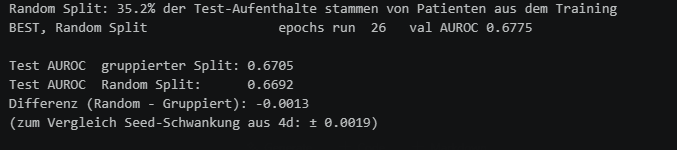

**Ergebnis:** Beim Random Split stammen 35,2 % der Test-Aufenthalte von Patient:innen, die mit einem anderen Aufenthalt auch im Trainingsset vorkommen. Die Test-AUROC beträgt beim Random Split 0,669, beim gruppierten Split 0,671. Die Differenz von −0,001 ist kleiner als die Seed-Schwankung aus 4d (± 0,002), es gibt also keinen messbaren Unterschied.

**Erwartete Richtung:** Eigentlich würde man beim Random Split ein besseres Ergebnis erwarten. Wenn dieselbe Person im Training und im Test vorkommt, kann das Modell sie an ähnlichen Merkmalen wiedererkennen (Data Leakage), und die Leistung wird zu optimistisch geschätzt. Auf dem Validierungsset sehen wir diese Richtung auch (0,678 beim Random Split vs. 0,664 beim gruppierten Split), auf dem Testset aber nicht.

**Mögliche Gründe, warum der Effekt hier so klein ist:**
- Ca. 65 % der Test-Aufenthalte stammen trotzdem von neuen Patient:innen, da die meisten Patient:innen nur einen Aufenthalt haben (siehe 2b).
- Unser finales Modell ist sehr klein (32 Neuronen) und stark regularisiert (Dropout, Early Stopping). Es kann einzelne Patient:innen kaum auswendig lernen. Ein großes Netz ohne Regularisierung würde vermutlich stärker vom Leakage profitieren.
- Ein Teil der Vorgeschichte steckt bereits erlaubt in den Features (z. B. number_inpatient).
- Beide Splits haben unterschiedliche Testsets. Ein Teil des Unterschieds ist daher Zufall durch die Aufteilung. Für eine sichere Aussage müsste man beide Varianten mit mehreren Split-Seeds wiederholen.

**Fazit:** Bei diesem Modell und Datensatz ist der Leakage-Effekt nicht messbar. Trotzdem ist der gruppierte Split die richtige Wahl, weil nur er die echte Situation abbildet: Das Modell soll im Einsatz neue Patient:innen beurteilen.